In [15]:
from pathlib import Path
import pandas as pd

VALIDATION_DIR = Path("validation")

# Fill in only the time (HHMMSS) of the session per test; the date follows from the participant.
# Leave a test as None if it was not recorded.
PARTICIPANTS = {
    1: {
        "label": "inside_dataset",
        "date": "20261020",
        "tests": {
            "15 to 5":        "142217",
            "5 to 15":        "142244",
            "12 to 6":        "142311",
            "6 to 12":        "142335",
            "10 to 4":        "142406",
            "4 to 10":        "142436",
            "16 to 12 to 8":  "142508",
            "8 to 12 to 16":  "142541",
            "12 to 8 to 4":   "142613",
            "4 to 8 to 12":   "142644",
        },
    },
    2: {
        "label": "inside_dataset",
        "date": "20261020",
        "tests": {
            "15 to 5":        "143857",
            "5 to 15":        "143923",
            "12 to 6":        "143947",
            "6 to 12":        "144015",
            "10 to 4":        "144044",
            "4 to 10":        "144112",
            "16 to 12 to 8":  "144150",
            "8 to 12 to 16":  "144218",
            "12 to 8 to 4":   "144249",
            "4 to 8 to 12":   "144313",
        },
    },
    3: {
        "label": "inside_dataset",
        "date": "20261020",
        "tests": {
            "15 to 5":        "145502",
            "5 to 15":        "145524",
            "12 to 6":        "145547",
            "6 to 12":        "145612",
            "10 to 4":        "145632",
            "4 to 10":        "145653",
            "16 to 12 to 8":  "145724",
            "8 to 12 to 16":  "145749",
            "12 to 8 to 4":   "145814",
            "4 to 8 to 12":   "145837",
        },
    },
    4: {
        "label": "inside_dataset",
        "date": "20261020",
        "tests": {
            "15 to 5":        "155740",
            "5 to 15":        "155818",
            "12 to 6":        "155923",
            "6 to 12":        "155958",
            "10 to 4":        "160042",
            "4 to 10":        "160437",
            "16 to 12 to 8":  "160542",
            "8 to 12 to 16":  "160621",
            "12 to 8 to 4":   "160658",
            "4 to 8 to 12":   "160737",
        },
    },
    5: {
        "label": "outside_dataset",
        "date": "20261020",
        "tests": {
            "15 to 5":        "151057",  
            "5 to 15":        "151239",
            "12 to 6":        "151320",
            "6 to 12":        "151348",
            "10 to 4":        "151425",
            "4 to 10":        "151456",
            "16 to 12 to 8":  "151530",
            "8 to 12 to 16":  "151601",
            "12 to 8 to 4":   "151630",
            "4 to 8 to 12":   "151700",
        },
    },
    6: {
        "label": "outside_dataset",
        "date": "20261021",
        "tests": {
            "15 to 5":        "105021",
            "5 to 15":        "105055",
            "12 to 6":        "105240",
            "6 to 12":        "105522",
            "10 to 4":        "105603",
            "4 to 10":        "105635",
            "16 to 12 to 8":  "105719",
            "8 to 12 to 16":  "105756",
            "12 to 8 to 4":   "105835",
            "4 to 8 to 12":   "105906",
        },
    },
    7: {
        "label": "outside_dataset",
        "date": "20261021",
        "tests": {
            "15 to 5":        "110554",
            "5 to 15":        "110642",
            "12 to 6":        "110728",
            "6 to 12":        "110822",
            "10 to 4":        "110925",
            "4 to 10":        "111030",
            "16 to 12 to 8":  "111125",
            "8 to 12 to 16":  "111227",
            "12 to 8 to 4":   "111355",
            "4 to 8 to 12":   "111446",
        },
    },
    8: {
        "label": "outside_dataset",
        "date": "20261021",
        "tests": {
            "15 to 5":        "112122",
            "5 to 15":        "112215",
            "12 to 6":        "112303",
            "6 to 12":        "112356",
            "10 to 4":        "112448",
            "4 to 10":        "112538",
            "16 to 12 to 8":  "112658",
            "8 to 12 to 16":  "112745",
            "12 to 8 to 4":   "112836",
            "4 to 8 to 12":   "112925",
        },
    },
}

rows = []
for participant, cfg in PARTICIPANTS.items():
    for test, time in cfg["tests"].items():
        if time is None:
            continue
        session = f"session_{cfg['date']}_{time}"
        path = VALIDATION_DIR / session
        if not path.is_dir():
            raise FileNotFoundError(f"participant {participant}, test '{test}': {path} not found")
        rows.append({
            "participant": participant,
            "label": cfg["label"],
            "test": test,
            "session": session,
            "path": path,
        })

dataset = pd.DataFrame(rows)

duplicates = dataset[dataset["session"].duplicated(keep=False)]
if not duplicates.empty:
    raise ValueError(f"session assigned to more than one test:\n{duplicates}")

# predictions.csv per session, keyed by session name
predictions = {row.session: pd.read_csv(row.path / "predictions.csv") for row in dataset.itertuples()}

assigned = set(dataset["session"])
unassigned = sorted(p.name for p in VALIDATION_DIR.glob("session_*") if p.name not in assigned)
print(f"{len(dataset)} sessions assigned, {len(unassigned)} sessions in {VALIDATION_DIR} not assigned")
dataset

80 sessions assigned, 10 sessions in validation not assigned


,participant,label,test,session,path
0,1,inside_dataset,15 to 5,session_20261020_142217,validation/session_20261020_142217
1,1,inside_dataset,5 to 15,session_20261020_142244,validation/session_20261020_142244
2,1,inside_dataset,12 to 6,session_20261020_142311,validation/session_20261020_142311
3,1,inside_dataset,6 to 12,session_20261020_142335,validation/session_20261020_142335
4,1,inside_dataset,10 to 4,session_20261020_142406,validation/session_20261020_142406
...,...,...,...,...,...
75,8,outside_dataset,4 to 10,session_20261021_112538,validation/session_20261021_112538
76,8,outside_dataset,16 to 12 to 8,session_20261021_112658,validation/session_20261021_112658
77,8,outside_dataset,8 to 12 to 16,session_20261021_112745,validation/session_20261021_112745
78,8,outside_dataset,12 to 8 to 4,session_20261021_112836,validation/session_20261021_112836


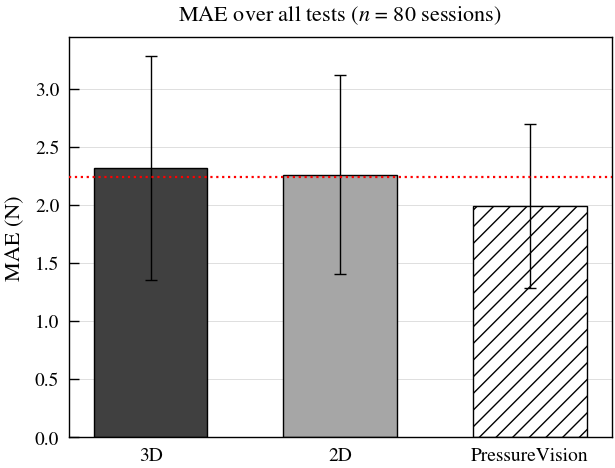

,mean,std
3D,2.318,0.965
2D,2.260,0.858
PressureVision,1.993,0.706


In [16]:
import matplotlib.pyplot as plt
import numpy as np

# IEEE style: double column (7.16 in), Times-like serif, 8 pt, grayscale + hatching
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "hatch.linewidth": 0.5,
    "figure.dpi": 200,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

MODELS = {"3D": "3D", "2D": "2D", "PressureVision": "PressureVision"}
STYLES = [
    {"facecolor": "0.25", "hatch": ""},
    {"facecolor": "0.65", "hatch": ""},
    {"facecolor": "white", "hatch": "////"},
]
TESTS = list(PARTICIPANTS[1]["tests"])
# Reference lines: zero error of the force sensor after unloading (411 lifts in the training sessions),
# matched to the metric: mean |offset| for MAE, RMS offset for RMSE.
MAE_REF_N = 2.24
RMSE_REF_N = 3.0
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def session_mae(df, model):
    scored = df[df["usable"] & df[f"{model}_n"].notna()]
    return (scored[f"{model}_n"] - scored["true_n"]).abs().mean()


mae = dataset[["participant", "test", "session"]].copy()
for model in MODELS:
    mae[model] = [session_mae(predictions[s], model) for s in mae["session"]]

# MAE over all tests: mean over the sessions of the per-session MAE
mae_overall = mae[list(MODELS)].agg(["mean", "std"]).T

fig, ax = plt.subplots(figsize=(3.5, 2.6))
x = np.arange(len(MODELS))
for i, (model, name) in enumerate(MODELS.items()):
    ax.bar(
        x[i],
        mae_overall.loc[model, "mean"],
        0.6,
        yerr=mae_overall.loc[model, "std"],
        edgecolor="black",
        linewidth=0.5,
        error_kw={"elinewidth": 0.5, "capsize": 2, "capthick": 0.5},
        **STYLES[i],
    )
ax.axhline(MAE_REF_N, color="red", linestyle=":", linewidth=0.8, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(list(MODELS.values()))
ax.set_ylabel("MAE (N)")
ax.set_title(f"MAE over all tests ($n$ = {len(mae)} sessions)")
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linewidth=0.3, color="0.85")

fig.savefig(FIG_DIR / "mae_overall.pdf")
fig.savefig(FIG_DIR / "mae_overall.png")
plt.show()
mae_overall.round(3)


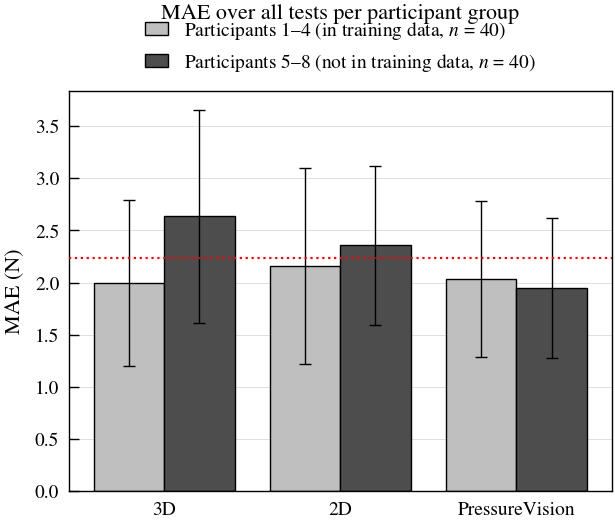

3D            2D        PressureVision       
                  mean    std   mean    std           mean    std
label                                                            
inside_dataset   1.999  0.797  2.161  0.942          2.037  0.746
outside_dataset  2.637  1.021  2.359  0.764          1.950  0.670

In [17]:
GROUP_COLORS = {"inside_dataset": "0.75", "outside_dataset": "0.3"}
GROUP_NAMES = {"inside_dataset": "In training data", "outside_dataset": "Not in training data"}
GROUPS = list(GROUP_COLORS)
mae["label"] = mae["participant"].map(lambda p: PARTICIPANTS[p]["label"])

# MAE over all tests per group: mean over the sessions of the per-session MAE
mae_overall_group = mae.groupby("label")[list(MODELS)].agg(["mean", "std"]).reindex(GROUPS)

fig, ax = plt.subplots(figsize=(3.5, 2.6))
x = np.arange(len(MODELS))
group_width = 0.8 / len(GROUPS)
for j, label in enumerate(GROUPS):
    members = [p for p in PARTICIPANTS if PARTICIPANTS[p]["label"] == label]
    n_sessions = (mae["label"] == label).sum()
    ax.bar(
        x + (j - (len(GROUPS) - 1) / 2) * group_width,
        [mae_overall_group.loc[label, (model, "mean")] for model in MODELS],
        group_width,
        yerr=[mae_overall_group.loc[label, (model, "std")] for model in MODELS],
        label=f"Participants {members[0]}–{members[-1]} ({GROUP_NAMES[label].lower()}, $n$ = {n_sessions})",
        facecolor=GROUP_COLORS[label],
        edgecolor="black",
        linewidth=0.5,
        error_kw={"elinewidth": 0.5, "capsize": 2, "capthick": 0.5},
    )
ax.axhline(MAE_REF_N, color="red", linestyle=":", linewidth=0.8, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(list(MODELS.values()))
ax.set_ylabel("MAE (N)")
ax.set_title("MAE over all tests per participant group", pad=26)
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linewidth=0.3, color="0.85")
ax.legend(ncol=1, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handlelength=1.2)

fig.savefig(FIG_DIR / "mae_overall_per_group.pdf")
fig.savefig(FIG_DIR / "mae_overall_per_group.png")
plt.show()
mae_overall_group.round(3)


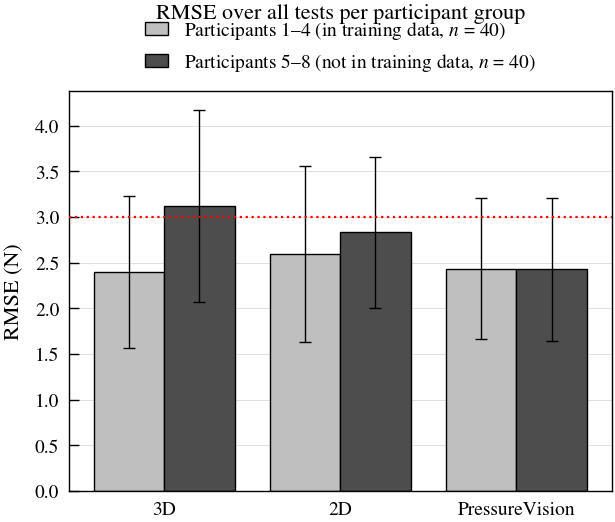

3D            2D        PressureVision       
                  mean    std   mean    std           mean    std
label                                                            
inside_dataset   2.402  0.831  2.592  0.965          2.437  0.771
outside_dataset  3.123  1.053  2.835  0.828          2.426  0.785

In [18]:
def session_rmse_all(df, model):
    scored = df[df["usable"] & df[f"{model}_n"].notna()]
    return np.sqrt(((scored[f"{model}_n"] - scored["true_n"]) ** 2).mean())


rmse_all = dataset[["participant", "test", "session"]].copy()
for model in MODELS:
    rmse_all[model] = [session_rmse_all(predictions[s], model) for s in rmse_all["session"]]
rmse_all["label"] = rmse_all["participant"].map(lambda p: PARTICIPANTS[p]["label"])

# RMSE over all tests per group: mean over the sessions of the per-session RMSE
rmse_overall_group = rmse_all.groupby("label")[list(MODELS)].agg(["mean", "std"]).reindex(GROUPS)

fig, ax = plt.subplots(figsize=(3.5, 2.6))
x = np.arange(len(MODELS))
group_width = 0.8 / len(GROUPS)
for j, label in enumerate(GROUPS):
    members = [p for p in PARTICIPANTS if PARTICIPANTS[p]["label"] == label]
    n_sessions = (rmse_all["label"] == label).sum()
    ax.bar(
        x + (j - (len(GROUPS) - 1) / 2) * group_width,
        [rmse_overall_group.loc[label, (model, "mean")] for model in MODELS],
        group_width,
        yerr=[rmse_overall_group.loc[label, (model, "std")] for model in MODELS],
        label=f"Participants {members[0]}–{members[-1]} ({GROUP_NAMES[label].lower()}, $n$ = {n_sessions})",
        facecolor=GROUP_COLORS[label],
        edgecolor="black",
        linewidth=0.5,
        error_kw={"elinewidth": 0.5, "capsize": 2, "capthick": 0.5},
    )
ax.axhline(RMSE_REF_N, color="red", linestyle=":", linewidth=0.8, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(list(MODELS.values()))
ax.set_ylabel("RMSE (N)")
ax.set_title("RMSE over all tests per participant group", pad=26)
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linewidth=0.3, color="0.85")
ax.legend(ncol=1, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handlelength=1.2)

fig.savefig(FIG_DIR / "rmse_overall_per_group.pdf")
fig.savefig(FIG_DIR / "rmse_overall_per_group.png")
plt.show()
rmse_overall_group.round(3)


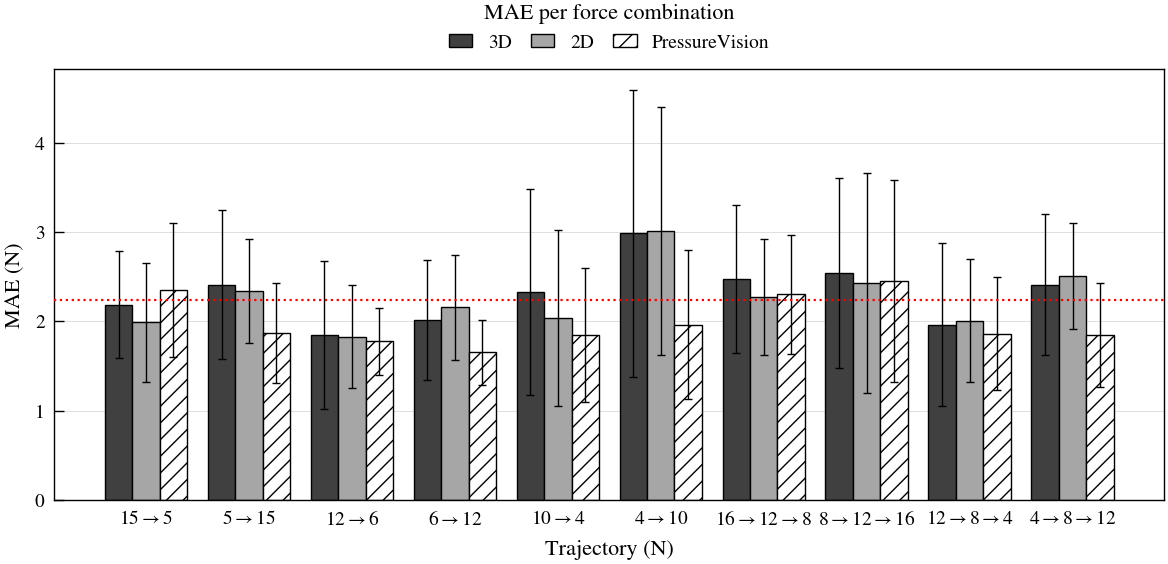

3D            2D        PressureVision       
                mean    std   mean    std           mean    std
test                                                           
15 to 5        2.187  0.599  1.993  0.665          2.349  0.748
5 to 15        2.411  0.835  2.344  0.581          1.868  0.559
12 to 6        1.850  0.826  1.830  0.579          1.776  0.371
6 to 12        2.015  0.668  2.157  0.588          1.654  0.367
10 to 4        2.327  1.151  2.042  0.986          1.849  0.750
4 to 10        2.989  1.608  3.012  1.388          1.964  0.831
16 to 12 to 8  2.479  0.826  2.272  0.650          2.303  0.670
8 to 12 to 16  2.542  1.068  2.429  1.228          2.453  1.126
12 to 8 to 4   1.966  0.911  2.010  0.686          1.864  0.632
4 to 8 to 12   2.412  0.792  2.514  0.594          1.852  0.584

In [19]:
mae_per_test = mae.groupby("test", sort=False)[list(MODELS)].agg(["mean", "std"]).reindex(TESTS)

fig, ax = plt.subplots(figsize=(7.16, 2.8))
x = np.arange(len(TESTS))
width = 0.8 / len(MODELS)
for i, (model, name) in enumerate(MODELS.items()):
    ax.bar(
        x + (i - (len(MODELS) - 1) / 2) * width,
        mae_per_test[(model, "mean")],
        width,
        yerr=mae_per_test[(model, "std")],
        label=name,
        edgecolor="black",
        linewidth=0.5,
        error_kw={"elinewidth": 0.5, "capsize": 1.5, "capthick": 0.5},
        **STYLES[i],
    )

ax.axhline(MAE_REF_N, color="red", linestyle=":", linewidth=0.8, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels([t.replace(" to ", r"$\rightarrow$") for t in TESTS])
ax.set_xlabel("Trajectory (N)")
ax.set_ylabel("MAE (N)")
ax.set_title("MAE per force combination", pad=18)
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linewidth=0.3, color="0.85")
ax.legend(ncol=len(MODELS), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handlelength=1.2, columnspacing=1.0)

fig.savefig(FIG_DIR / "mae_per_trajectory.pdf")
fig.savefig(FIG_DIR / "mae_per_trajectory.png")
plt.show()
mae_per_test.round(3)


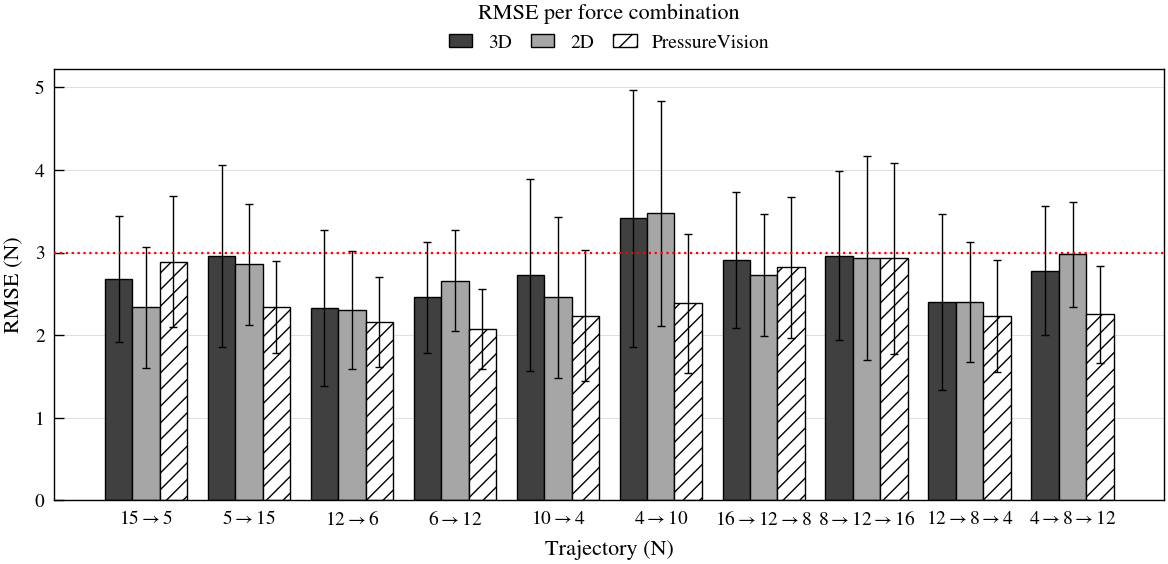

3D            2D        PressureVision       
                mean    std   mean    std           mean    std
test                                                           
15 to 5        2.684  0.762  2.336  0.737          2.888  0.796
5 to 15        2.956  1.103  2.860  0.735          2.339  0.558
12 to 6        2.325  0.946  2.299  0.715          2.160  0.547
6 to 12        2.457  0.674  2.661  0.611          2.077  0.483
10 to 4        2.725  1.165  2.459  0.973          2.236  0.789
4 to 10        3.417  1.558  3.477  1.364          2.388  0.842
16 to 12 to 8  2.909  0.825  2.726  0.741          2.822  0.854
8 to 12 to 16  2.963  1.027  2.934  1.239          2.930  1.155
12 to 8 to 4   2.403  1.070  2.404  0.727          2.227  0.679
4 to 8 to 12   2.782  0.782  2.981  0.637          2.250  0.589

In [20]:
rmse_per_test = rmse_all.groupby("test", sort=False)[list(MODELS)].agg(["mean", "std"]).reindex(TESTS)

fig, ax = plt.subplots(figsize=(7.16, 2.8))
x = np.arange(len(TESTS))
width = 0.8 / len(MODELS)
for i, (model, name) in enumerate(MODELS.items()):
    ax.bar(
        x + (i - (len(MODELS) - 1) / 2) * width,
        rmse_per_test[(model, "mean")],
        width,
        yerr=rmse_per_test[(model, "std")],
        label=name,
        edgecolor="black",
        linewidth=0.5,
        error_kw={"elinewidth": 0.5, "capsize": 1.5, "capthick": 0.5},
        **STYLES[i],
    )

ax.axhline(RMSE_REF_N, color="red", linestyle=":", linewidth=0.8, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels([t.replace(" to ", r"$\rightarrow$") for t in TESTS])
ax.set_xlabel("Trajectory (N)")
ax.set_ylabel("RMSE (N)")
ax.set_title("RMSE per force combination", pad=18)
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linewidth=0.3, color="0.85")
ax.legend(ncol=len(MODELS), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handlelength=1.2, columnspacing=1.0)

fig.savefig(FIG_DIR / "rmse_per_trajectory.pdf")
fig.savefig(FIG_DIR / "rmse_per_trajectory.png")
plt.show()
rmse_per_test.round(3)


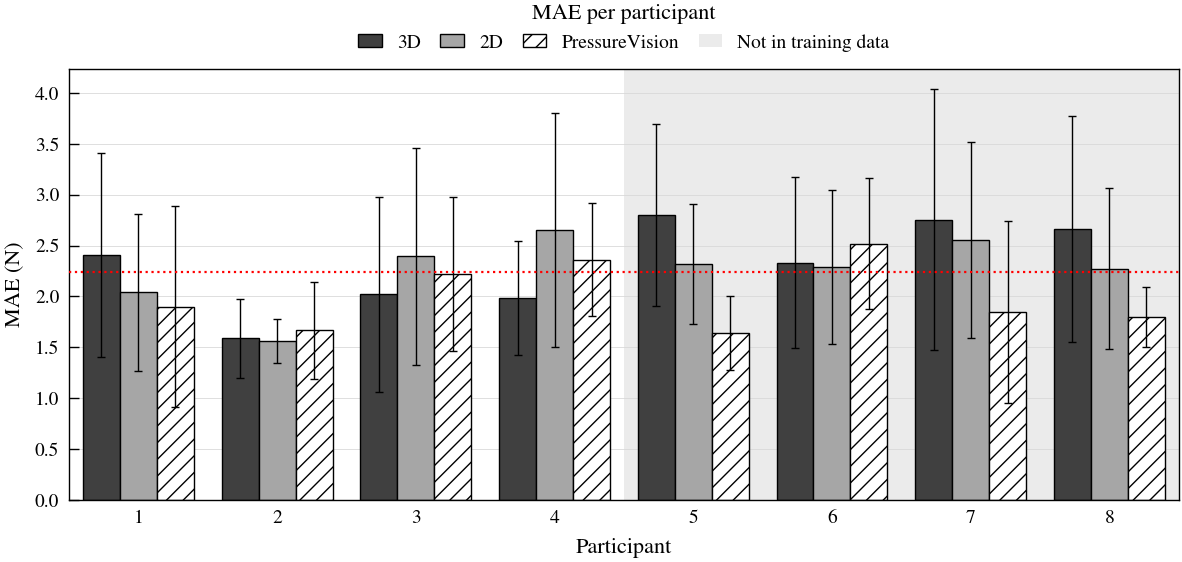

3D            2D        PressureVision       
              mean    std   mean    std           mean    std
participant                                                  
1            2.404  1.002  2.040  0.773          1.898  0.987
2            1.588  0.386  1.560  0.217          1.666  0.474
3            2.020  0.961  2.393  1.064          2.223  0.758
4            1.984  0.556  2.652  1.148          2.359  0.556
5            2.800  0.890  2.314  0.590          1.639  0.365
6            2.330  0.841  2.293  0.755          2.519  0.648
7            2.755  1.280  2.557  0.961          1.844  0.895
8            2.662  1.109  2.273  0.792          1.796  0.294

In [21]:
mae_per_participant = mae.groupby("participant")[list(MODELS)].agg(["mean", "std"])
participants = mae_per_participant.index.to_list()
outside = [PARTICIPANTS[p]["label"] == "outside_dataset" for p in participants]

fig, ax = plt.subplots(figsize=(7.16, 2.8))
x = np.arange(len(participants))
for xi, out in zip(x, outside):
    if out:
        ax.axvspan(xi - 0.5, xi + 0.5, facecolor="0.92", edgecolor="none", zorder=0)
for i, (model, name) in enumerate(MODELS.items()):
    ax.bar(
        x + (i - (len(MODELS) - 1) / 2) * width,
        mae_per_participant[(model, "mean")],
        width,
        yerr=mae_per_participant[(model, "std")],
        label=name,
        edgecolor="black",
        linewidth=0.5,
        error_kw={"elinewidth": 0.5, "capsize": 1.5, "capthick": 0.5},
        **STYLES[i],
    )
ax.bar(0, 0, color="0.92", label="Not in training data")

ax.axhline(MAE_REF_N, color="red", linestyle=":", linewidth=0.8, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels([str(p) for p in participants])
ax.set_xlim(-0.5, len(participants) - 0.5)
ax.set_xlabel("Participant")
ax.set_ylabel("MAE (N)")
ax.set_title("MAE per participant", pad=18)
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linewidth=0.3, color="0.85")
ax.legend(ncol=len(MODELS) + 1, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handlelength=1.2, columnspacing=1.0)

fig.savefig(FIG_DIR / "mae_per_participant.pdf")
fig.savefig(FIG_DIR / "mae_per_participant.png")
plt.show()
mae_per_participant.round(3)


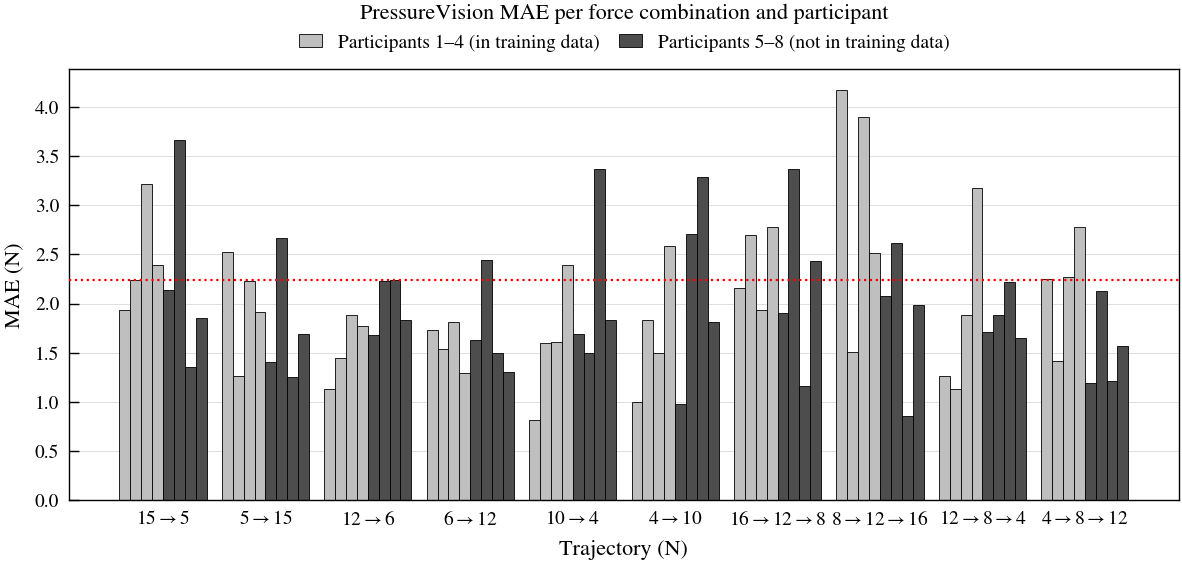

participant,1,2,3,4,5,6,7,8
test,,,,,,,,
15 to 5,1.938,2.236,3.214,2.396,2.136,3.658,1.358,1.856
5 to 15,2.522,1.265,2.229,1.913,1.407,2.669,1.255,1.688
12 to 6,1.134,1.446,1.885,1.769,1.675,2.232,2.236,1.833
6 to 12,1.730,1.535,1.814,1.289,1.626,2.438,1.494,1.305
10 to 4,0.815,1.594,1.609,2.395,1.687,1.496,3.366,1.828
4 to 10,0.999,1.837,1.496,2.589,0.982,2.710,3.282,1.812
16 to 12 to 8,2.156,2.697,1.931,2.777,1.905,3.365,1.161,2.434
8 to 12 to 16,4.176,1.505,3.895,2.510,2.073,2.617,0.860,1.986
12 to 8 to 4,1.266,1.134,1.879,3.174,1.709,1.879,2.214,1.652


In [22]:
model = "PressureVision"
mae_pv = mae.pivot(index="test", columns="participant", values=model).reindex(TESTS)
participants = mae_pv.columns.to_list()

fig, ax = plt.subplots(figsize=(7.16, 2.8))
x = np.arange(len(TESTS))
bar_width = 0.85 / len(participants)
for i, p in enumerate(participants):
    label = PARTICIPANTS[p]["label"]
    ax.bar(
        x + (i - (len(participants) - 1) / 2) * bar_width,
        mae_pv[p],
        bar_width,
        facecolor=GROUP_COLORS[label],
        edgecolor="black",
        linewidth=0.3,
    )
for label, color in GROUP_COLORS.items():
    members = [p for p in participants if PARTICIPANTS[p]["label"] == label]
    ax.bar(0, 0, facecolor=color, edgecolor="black", linewidth=0.3,
           label=f"Participants {members[0]}–{members[-1]} ({GROUP_NAMES[label].lower()})")

ax.axhline(MAE_REF_N, color="red", linestyle=":", linewidth=0.8, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels([t.replace(" to ", r"$\rightarrow$") for t in TESTS])
ax.set_xlabel("Trajectory (N)")
ax.set_ylabel("MAE (N)")
ax.set_title(f"{model} MAE per force combination and participant", pad=18)
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linewidth=0.3, color="0.85")
ax.legend(ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handlelength=1.2, columnspacing=1.0)

fig.savefig(FIG_DIR / "mae_pressurevision_per_trajectory_participant.pdf")
fig.savefig(FIG_DIR / "mae_pressurevision_per_trajectory_participant.png")
plt.show()
mae_pv.round(3)


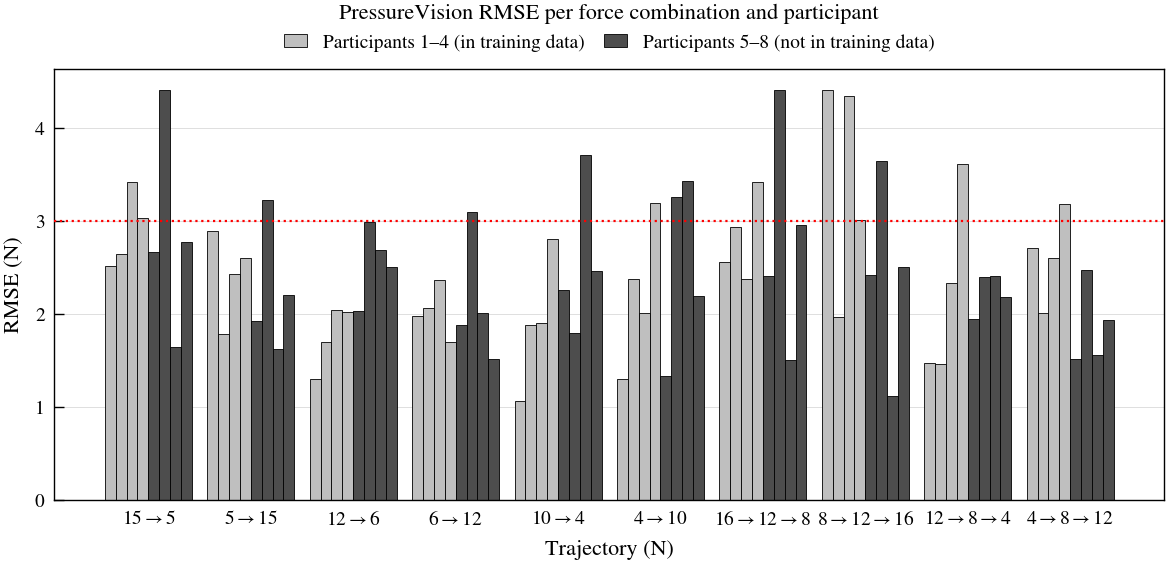

participant,1,2,3,4,5,6,7,8
test,,,,,,,,
15 to 5,2.515,2.643,3.420,3.032,2.664,4.413,1.647,2.770
5 to 15,2.895,1.791,2.434,2.600,1.926,3.230,1.624,2.210
12 to 6,1.299,1.697,2.047,2.027,2.029,2.994,2.689,2.501
6 to 12,1.980,2.064,2.370,1.702,1.877,3.096,2.007,1.518
10 to 4,1.062,1.884,1.901,2.802,2.259,1.800,3.712,2.468
4 to 10,1.306,2.381,2.009,3.192,1.332,3.261,3.429,2.193
16 to 12 to 8,2.564,2.935,2.381,3.421,2.405,4.414,1.501,2.956
8 to 12 to 16,4.412,1.966,4.343,3.013,2.421,3.650,1.125,2.510
12 to 8 to 4,1.476,1.459,2.332,3.613,1.948,2.394,2.411,2.180


In [23]:
model = "PressureVision"


def session_rmse(df, model):
    scored = df[df["usable"] & df[f"{model}_n"].notna()]
    return np.sqrt(((scored[f"{model}_n"] - scored["true_n"]) ** 2).mean())


rmse = dataset[["participant", "test", "session"]].copy()
rmse[model] = [session_rmse(predictions[s], model) for s in rmse["session"]]
rmse_pv = rmse.pivot(index="test", columns="participant", values=model).reindex(TESTS)
participants = rmse_pv.columns.to_list()

fig, ax = plt.subplots(figsize=(7.16, 2.8))
x = np.arange(len(TESTS))
bar_width = 0.85 / len(participants)
for i, p in enumerate(participants):
    label = PARTICIPANTS[p]["label"]
    ax.bar(
        x + (i - (len(participants) - 1) / 2) * bar_width,
        rmse_pv[p],
        bar_width,
        facecolor=GROUP_COLORS[label],
        edgecolor="black",
        linewidth=0.3,
    )
for label, color in GROUP_COLORS.items():
    members = [p for p in participants if PARTICIPANTS[p]["label"] == label]
    ax.bar(0, 0, facecolor=color, edgecolor="black", linewidth=0.3,
           label=f"Participants {members[0]}–{members[-1]} ({GROUP_NAMES[label].lower()})")

ax.axhline(RMSE_REF_N, color="red", linestyle=":", linewidth=0.8, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels([t.replace(" to ", r"$\rightarrow$") for t in TESTS])
ax.set_xlabel("Trajectory (N)")
ax.set_ylabel("RMSE (N)")
ax.set_title(f"{model} RMSE per force combination and participant", pad=18)
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linewidth=0.3, color="0.85")
ax.legend(ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handlelength=1.2, columnspacing=1.0)

fig.savefig(FIG_DIR / "rmse_pressurevision_per_trajectory_participant.pdf")
fig.savefig(FIG_DIR / "rmse_pressurevision_per_trajectory_participant.png")
plt.show()
rmse_pv.round(3)


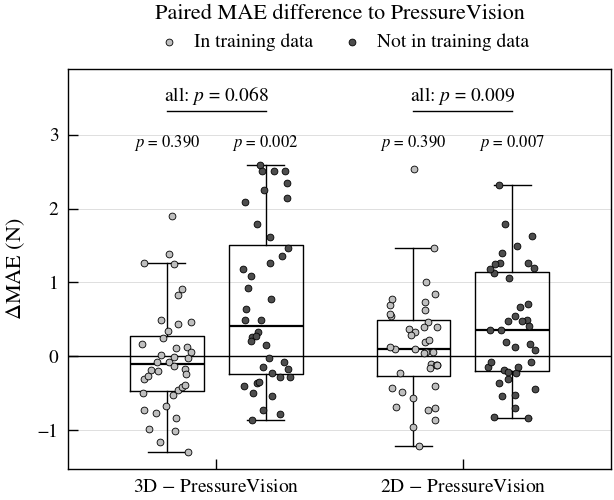

,model,group,n,median_delta,p
0,3D,inside_dataset,40,-0.1053,0.3900
1,3D,outside_dataset,40,0.4064,0.0021
2,3D,all,80,0.0384,0.0684
3,2D,inside_dataset,40,0.0951,0.3900
4,2D,outside_dataset,40,0.3548,0.0067
5,2D,all,80,0.1799,0.0092


In [24]:
from scipy.stats import wilcoxon

# Paired comparison: per session, how much worse each model is than PressureVision
BASELINE = "PressureVision"
COMPARED = [m for m in MODELS if m != BASELINE]

for model in COMPARED:
    mae[f"{model}_delta"] = mae[model] - mae[BASELINE]

fig, ax = plt.subplots(figsize=(3.5, 2.6))
rng = np.random.default_rng(0)
group_offset = 0.2
stats = []
for i, model in enumerate(COMPARED):
    for j, label in enumerate(GROUPS):
        delta = mae.loc[mae["label"] == label, f"{model}_delta"]
        pos = i + (j - 0.5) * 2 * group_offset
        ax.boxplot(
            delta, positions=[pos], widths=0.3, showfliers=False,
            medianprops={"color": "black", "linewidth": 0.8},
            boxprops={"linewidth": 0.5}, whiskerprops={"linewidth": 0.5}, capprops={"linewidth": 0.5},
        )
        ax.scatter(
            pos + rng.uniform(-0.1, 0.1, len(delta)), delta, s=6,
            facecolor=GROUP_COLORS[label], edgecolor="black", linewidth=0.3, zorder=3,
            label=f"{GROUP_NAMES[label]}" if i == 0 else None,
        )
        stats.append({"model": model, "group": label, "n": len(delta),
                      "median_delta": delta.median(), "p": wilcoxon(delta).pvalue})
    p_all = wilcoxon(mae[f"{model}_delta"]).pvalue
    stats.append({"model": model, "group": "all", "n": len(mae),
                  "median_delta": mae[f"{model}_delta"].median(), "p": p_all})

ax.axhline(0, color="black", linewidth=0.5, zorder=2)
stats = pd.DataFrame(stats)
ymax = mae[[f"{m}_delta" for m in COMPARED]].max().max()


def p_text(p):
    return f"$p$ = {p:.3f}" if p >= 0.001 else "$p$ < 0.001"


for i, model in enumerate(COMPARED):
    for j, label in enumerate(GROUPS):
        p = stats.query("model == @model and group == @label")["p"].item()
        ax.text(i + (j - 0.5) * 2 * group_offset, ymax * 1.06, p_text(p), ha="center", va="bottom", fontsize=6)
    p = stats.query("model == @model and group == 'all'")["p"].item()
    ax.plot([i - group_offset, i + group_offset], [ymax * 1.28] * 2, color="black", linewidth=0.5)
    ax.text(i, ymax * 1.3, f"all: {p_text(p)}", ha="center", va="bottom", fontsize=7)

ax.set_xticks(range(len(COMPARED)))
ax.set_xticklabels([f"{m} $-$ {BASELINE}" for m in COMPARED])
ax.set_xlim(-0.6, len(COMPARED) - 0.4)
ax.set_ylim(top=ymax * 1.5)
ax.set_ylabel(r"$\Delta$MAE (N)")
ax.set_title(f"Paired MAE difference to {BASELINE}", pad=18)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linewidth=0.3, color="0.85")
ax.legend(ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handletextpad=0.3, columnspacing=1.0)

fig.savefig(FIG_DIR / "mae_paired_difference.pdf")
fig.savefig(FIG_DIR / "mae_paired_difference.png")
plt.show()
stats.round(4)


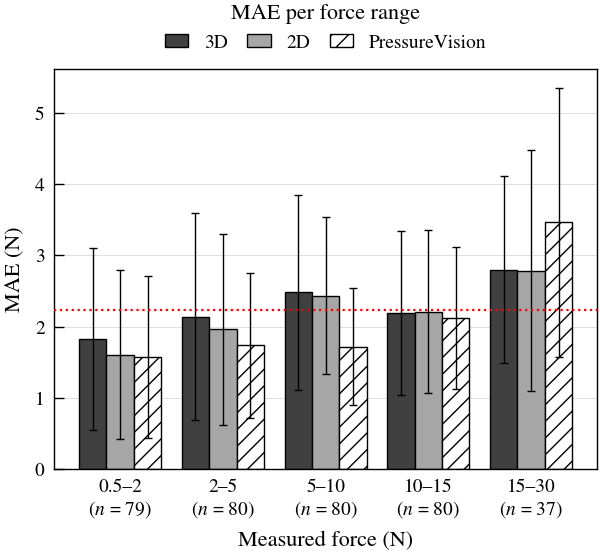

model,2D,3D,PressureVision,2D,3D,PressureVision
,mean,mean,mean,std,std,std
force_bin,,,,,,
0.5–2,1.608,1.825,1.574,1.184,1.281,1.143
2–5,1.963,2.138,1.736,1.337,1.455,1.022
5–10,2.437,2.482,1.720,1.105,1.369,0.817
10–15,2.211,2.194,2.122,1.148,1.152,0.992
15–30,2.787,2.803,3.464,1.689,1.317,1.889


In [25]:
# MAE per force range of the measured force (frames in contact only)
FORCE_BINS = [0.5, 2, 5, 10, 15, 30]
bin_labels = [f"{lo}–{hi}" for lo, hi in zip(FORCE_BINS[:-1], FORCE_BINS[1:])]

rows = []
for row in dataset.itertuples():
    df = predictions[row.session]
    df = df[df["usable"]].assign(force_bin=pd.cut(df["true_n"], FORCE_BINS, labels=bin_labels))
    for model in MODELS:
        scored = df[df[f"{model}_n"].notna()]
        err = (scored[f"{model}_n"] - scored["true_n"]).abs()
        for force_bin, e in err.groupby(scored["force_bin"], observed=True):
            rows.append({"session": row.session, "model": model, "force_bin": force_bin, "mae": e.mean(), "frames": len(e)})
mae_force = pd.DataFrame(rows)

# mean over sessions of the per-session MAE in each force range
mae_per_force = mae_force.pivot_table(index="force_bin", columns="model", values="mae", aggfunc=["mean", "std"], observed=False)
mae_per_force = mae_per_force.swaplevel(axis=1).reindex(bin_labels)
sessions_per_force = mae_force.query("model == @BASELINE").groupby("force_bin", observed=False)["session"].nunique().reindex(bin_labels)

fig, ax = plt.subplots(figsize=(3.5, 2.6))
x = np.arange(len(bin_labels))
for i, (model, name) in enumerate(MODELS.items()):
    ax.bar(
        x + (i - (len(MODELS) - 1) / 2) * width,
        mae_per_force[(model, "mean")],
        width,
        yerr=mae_per_force[(model, "std")],
        label=name,
        edgecolor="black",
        linewidth=0.5,
        error_kw={"elinewidth": 0.5, "capsize": 1.5, "capthick": 0.5},
        **STYLES[i],
    )
ax.axhline(MAE_REF_N, color="red", linestyle=":", linewidth=0.8, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels([f"{b}\n($n$ = {n})" for b, n in zip(bin_labels, sessions_per_force)])
ax.set_xlabel("Measured force (N)")
ax.set_ylabel("MAE (N)")
ax.set_title("MAE per force range", pad=18)
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linewidth=0.3, color="0.85")
ax.legend(ncol=len(MODELS), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handlelength=1.2, columnspacing=1.0)

fig.savefig(FIG_DIR / "mae_per_force_range.pdf")
fig.savefig(FIG_DIR / "mae_per_force_range.png")
plt.show()
mae_per_force.round(3)


In [26]:
# Wilcoxon signed-rank on participant means: one value per participant, so the 8 values are independent.
# Exact two-sided test: with n = 4 per group the smallest possible p is 0.125, so only the pooled n = 8 can reach p < 0.05.
delta_cols = [f"{m}_delta" for m in COMPARED]
delta_per_participant = mae.groupby(["participant", "label"])[delta_cols].mean().reset_index()

rows = []
for model in COMPARED:
    col = f"{model}_delta"
    for group in GROUPS + ["all"]:
        d = delta_per_participant[col] if group == "all" else delta_per_participant.loc[delta_per_participant["label"] == group, col]
        rows.append({"model": model, "group": group, "n": len(d),
                     "mean_delta": d.mean(), "median_delta": d.median(), "p": wilcoxon(d, method="exact").pvalue})
participant_stats = pd.DataFrame(rows)

print(delta_per_participant.round(3).to_string(index=False))
participant_stats.round(4)


 participant           label  3D_delta  2D_delta
           1  inside_dataset     0.506     0.142
           2  inside_dataset    -0.078    -0.107
           3  inside_dataset    -0.203     0.170
           4  inside_dataset    -0.375     0.293
           5 outside_dataset     1.161     0.675
           6 outside_dataset    -0.190    -0.227
           7 outside_dataset     0.910     0.713
           8 outside_dataset     0.866     0.477


,model,group,n,mean_delta,median_delta,p
0,3D,inside_dataset,4,-0.0376,-0.1407,0.8750
1,3D,outside_dataset,4,0.6871,0.8884,0.2500
2,3D,all,8,0.3248,0.2139,0.3125
3,2D,inside_dataset,4,0.1247,0.1560,0.2500
4,2D,outside_dataset,4,0.4093,0.5758,0.2500
5,2D,all,8,0.2670,0.2319,0.0781


In [27]:
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

# Linear mixed model on the per-session paired difference, random intercept per participant:
#   delta ~ 0 + group + (1 | participant)
# Every group coefficient is the mean difference to PressureVision in that group, corrected for the
# sessions of one participant being correlated. A second fit with an intercept tests whether the
# difference changes between participants in and outside the training data.
# Powell: the default gradient optimizers do not converge for every fit.
rows = []
for model in COMPARED:
    data = mae.rename(columns={f"{model}_delta": "delta"})
    fits = {
        "per group": smf.mixedlm("delta ~ 0 + C(label)", data, groups=data["participant"]).fit(reml=True, method="powell"),
        "all": smf.mixedlm("delta ~ 1", data, groups=data["participant"]).fit(reml=True, method="powell"),
        "outside vs inside": smf.mixedlm("delta ~ C(label)", data, groups=data["participant"]).fit(reml=True, method="powell"),
    }
    for fit_name, fit in fits.items():
        ci = fit.conf_int()
        for term in fit.fe_params.index:
            if fit_name == "outside vs inside" and term == "Intercept":
                continue
            rows.append({
                "model": model,
                "fit": fit_name,
                "term": term.replace("C(label)", "").strip("[]").replace("T.", ""),
                "estimate": fit.fe_params[term],
                "ci_low": ci.loc[term, 0],
                "ci_high": ci.loc[term, 1],
                "p": fit.pvalues[term],
                "participant_sd": np.sqrt(fit.cov_re.iloc[0, 0]),
                "converged": fit.converged,
            })
mixed_stats = pd.DataFrame(rows)

# Holm correction over the per-group tests (2 models x 2 groups)
per_group = mixed_stats["fit"] == "per group"
mixed_stats.loc[per_group, "p_holm"] = multipletests(mixed_stats.loc[per_group, "p"], method="holm")[1]
mixed_stats.round(4)


,model,fit,term,estimate,ci_low,ci_high,p,participant_sd,converged,p_holm
0,3D,per group,inside_dataset,-0.0376,-0.5299,0.4547,0.8810,0.4267,True,0.9013
1,3D,per group,outside_dataset,0.6871,0.1949,1.1794,0.0062,0.4267,True,0.0249
2,3D,all,Intercept,0.3248,-0.0947,0.7442,0.1291,0.5442,True,NaN
3,3D,outside vs inside,outside_dataset,0.7248,0.0286,1.4209,0.0413,0.4267,True,NaN
4,2D,per group,inside_dataset,0.1247,-0.1993,0.4487,0.4507,0.2417,True,0.9013
5,2D,per group,outside_dataset,0.4093,0.0853,0.7334,0.0133,0.2417,True,0.0398
6,2D,all,Intercept,0.2670,0.0301,0.5039,0.0271,0.2568,True,NaN
7,2D,outside vs inside,outside_dataset,0.2846,-0.1736,0.7429,0.2234,0.2417,True,NaN
